# 12 - Model Comparison (Experiment 1)

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Compare all 8 models from Experiment 1 on the same PhiUSIIL test set and choose the best model.

**Input:** `results/metrics/` (one results table for each model)

**Output:** `results/comparison/`

## Setup

Every model notebook saved its results in `results/metrics/` with the same shared functions. So all scores here were calculated in the same way, on the same test set, and can be compared fairly.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path("..").resolve()))
from src.data import PROCESSED_DIR, TARGET
from src.evaluation import RESULTS_DIR

METRICS_DIR = RESULTS_DIR / "metrics"
SAVE_DIR = RESULTS_DIR / "comparison"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "xgboost": "Supervised",
    "random_forest": "Supervised",
    "decision_tree": "Supervised",
    "logistic_regression": "Supervised",
    "knn": "Supervised",
    "svm": "Supervised",
    "naive_bayes": "Supervised",
    "isolation_forest": "Unsupervised",
}

METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
COLOR = "#4C72B0"

## 1. Load the Results

We load the results table of each model and join them into one table. We also count the test URLs, so we can turn accuracy into the number of mistakes. With scores this close to 100%, the number of mistakes is much easier to compare.

In [2]:
all_results = pd.concat(
    [pd.read_csv(METRICS_DIR / f"{name}.csv").assign(Type=model_type) for name, model_type in MODELS.items()],
    ignore_index=True,
)

test_size = len(pd.read_csv(PROCESSED_DIR / "test.csv", usecols=[TARGET]))
all_results["Mistakes"] = ((1 - all_results["Accuracy"]) * test_size).round().astype(int)

print(f"Models: {all_results['Model'].nunique()}")
print(f"Test URLs: {test_size:,}")

Models: 8
Test URLs: 47,074


## 2. Test Set Results

This is the main comparison. Every model was trained on the full training set with its best settings and tested once on the same 47,074 test URLs, using all 69 features. The table is sorted by F1-score.

In [3]:
test_table = (
    all_results[all_results["Experiment"] == "Test set - All features"]
    .set_index("Model")[["Type", *METRIC_COLS, "Mistakes", "Train Time (s)"]]
    .sort_values(["F1", "Mistakes"], ascending=[False, True])
)
test_table.round(4)

,Type,Accuracy,Precision,Recall,F1,ROC-AUC,Mistakes,Train Time (s)
Model,,,,,,,,
Decision Tree,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,0,0.6433
XGBoost,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,1,2.6984
Random Forest,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,1,13.4427
SVM,Supervised,1.0000,1.0000,0.9999,1.0000,1.0000,2,3.5873
Logistic Regression,Supervised,0.9999,1.0000,0.9997,0.9999,1.0000,6,0.5311
Naive Bayes,Supervised,0.9997,0.9995,1.0000,0.9997,0.9999,12,0.4819
KNN,Supervised,0.9993,0.9999,0.9985,0.9992,0.9997,32,0.9004
Isolation Forest,Unsupervised,0.8989,0.8727,0.8935,0.8830,0.9606,4761,2.4596


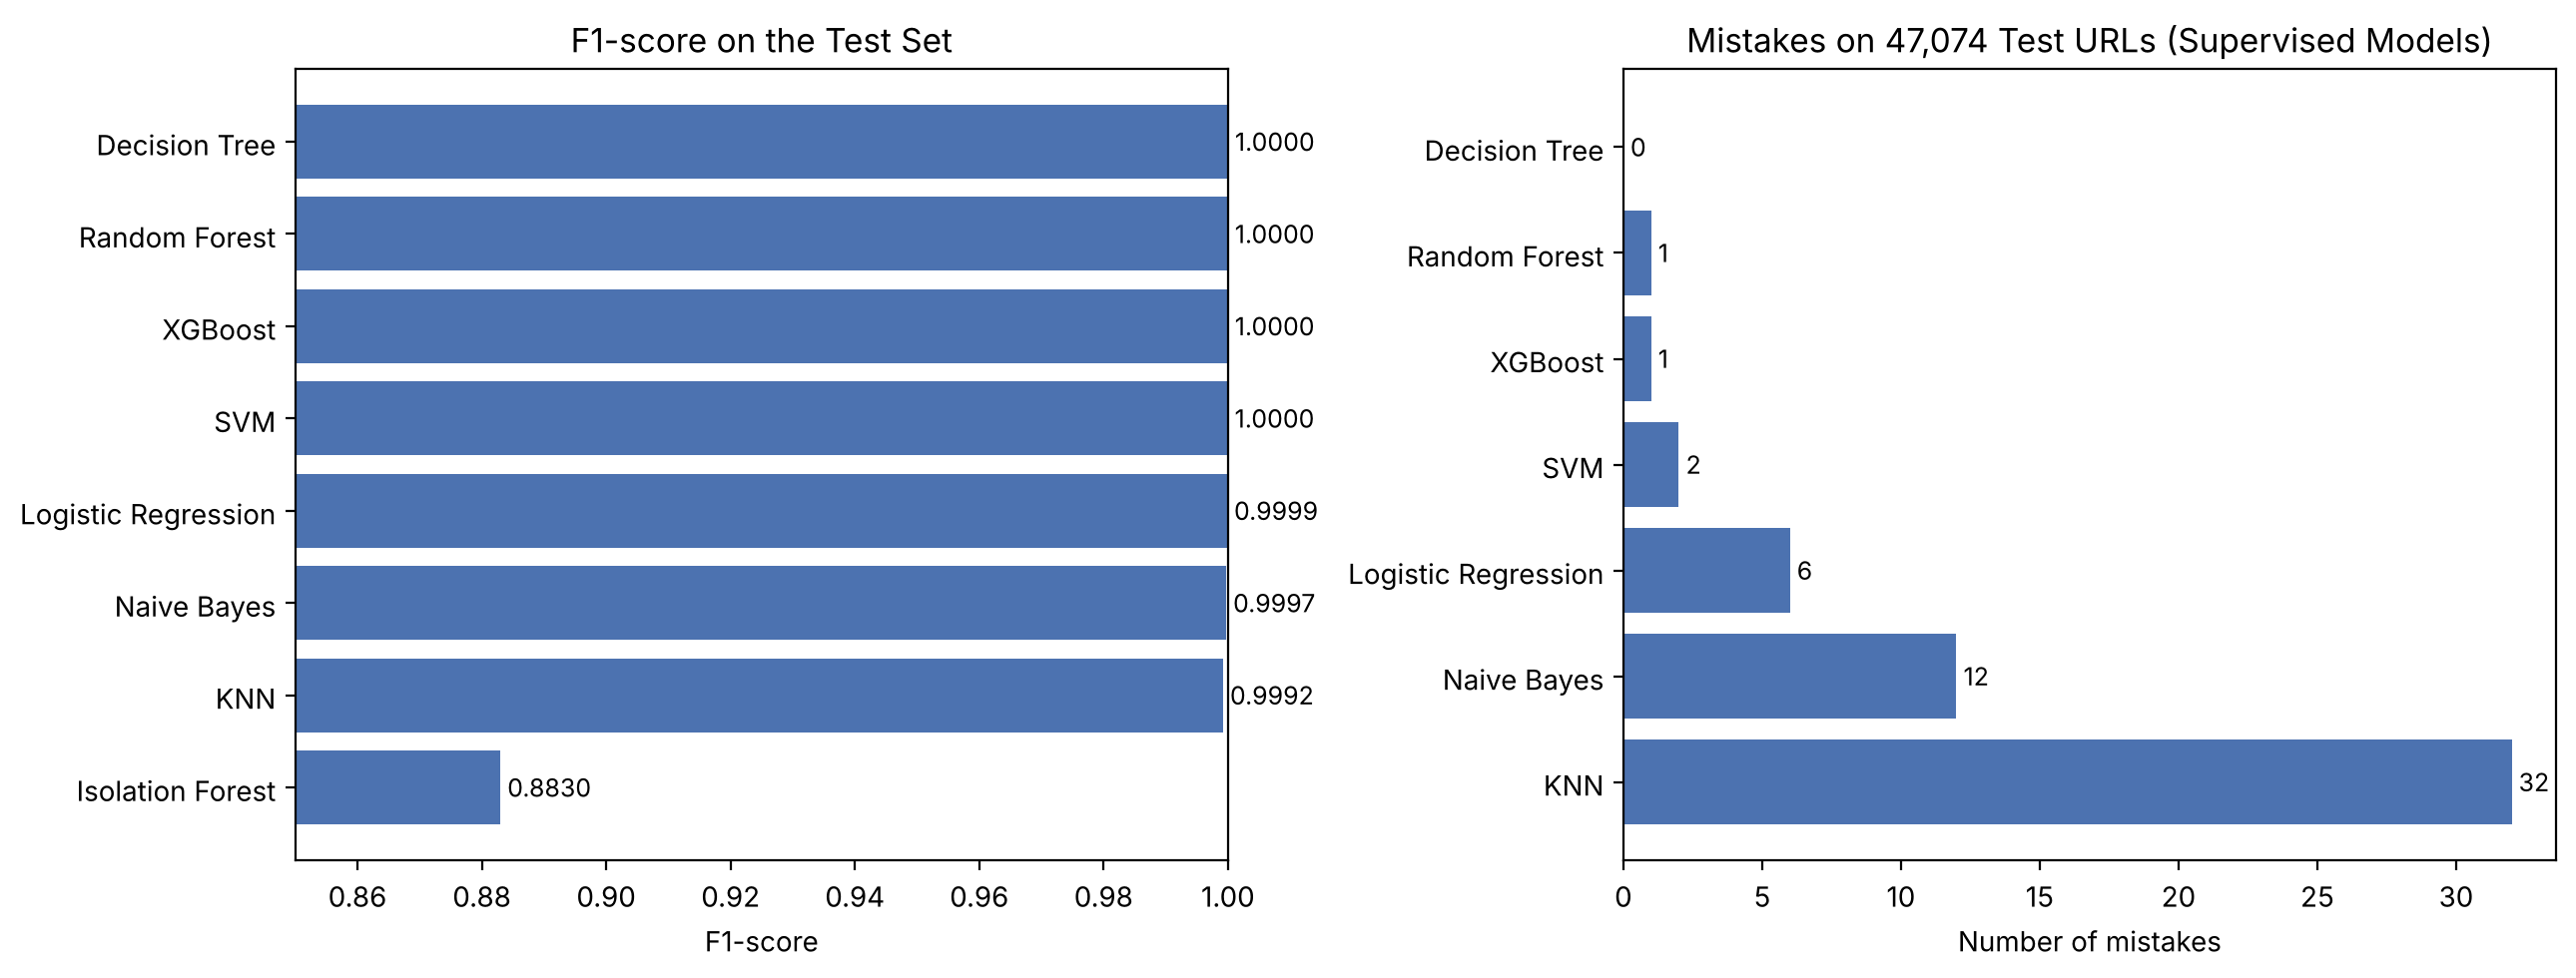

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

f1 = test_table["F1"].sort_values()
axes[0].barh(f1.index, f1.values, color=COLOR)
axes[0].set_xlim(0.85, 1.0)
axes[0].set_title("F1-score on the Test Set")
axes[0].set_xlabel("F1-score")
for i, v in enumerate(f1.values):
    axes[0].text(v, i, f" {v:.4f}", va="center", fontsize=9)

supervised = test_table[test_table["Type"] == "Supervised"]["Mistakes"].sort_values(ascending=False)
axes[1].barh(supervised.index, supervised.values, color=COLOR)
axes[1].set_title("Mistakes on 47,074 Test URLs (Supervised Models)")
axes[1].set_xlabel("Number of mistakes")
for i, v in enumerate(supervised.values):
    axes[1].text(v, i, f" {v}", va="center", fontsize=9)

fig.tight_layout()
fig.savefig(SAVE_DIR / "test_set_comparison.png", dpi=300)
plt.show()

Isolation Forest is left out of the mistakes chart because it made thousands of mistakes, which would hide the small differences between the other models.

## 3. Cross-Validation vs Test Set

If a model is much better in cross-validation than on the test set, it may be overfitting. Here we put the two F1-scores side by side.

In [5]:
cv_f1 = all_results[all_results["Experiment"] == "Cross-validation"].set_index("Model")["F1"]

overfit_table = pd.DataFrame({
    "Cross-validation F1": cv_f1,
    "Test F1": test_table["F1"],
})
overfit_table["Difference"] = (overfit_table["Cross-validation F1"] - overfit_table["Test F1"]).round(4).replace(-0.0, 0.0)
overfit_table.loc[test_table.index].round(4)

,Cross-validation F1,Test F1,Difference
Model,,,
Decision Tree,1.0000,1.0000,0.0000
XGBoost,1.0000,1.0000,0.0000
Random Forest,1.0000,1.0000,0.0000
SVM,0.9999,1.0000,0.0000
Logistic Regression,0.9999,0.9999,0.0001
Naive Bayes,0.9996,0.9997,-0.0001
KNN,0.9986,0.9992,-0.0006
Isolation Forest,0.8796,0.8830,-0.0033


## 4. Feature Set Comparison

Each model was also trained on two smaller feature sets:

- **Original features only:** shows if our new features from feature engineering helped.
- **Without `URLSimilarityIndex`:** shows if the model still works without its strongest feature.

We compare the number of mistakes on the test set.

In [6]:
feature_experiments = {
    "Test set - All features": "All features",
    "Test set - Original features only": "Original features only",
    "Test set - Without URLSimilarityIndex": "Without URLSimilarityIndex",
}

feature_table = (
    all_results[all_results["Experiment"].isin(feature_experiments)]
    .assign(Experiment=lambda df: df["Experiment"].map(feature_experiments))
    .pivot(index="Model", columns="Experiment", values="Mistakes")
    .loc[test_table.index, list(feature_experiments.values())]
)
feature_table

Experiment,All features,Original features only,Without URLSimilarityIndex
Model,,,
Decision Tree,0,0,245
XGBoost,1,1,4
Random Forest,1,1,1
SVM,2,3,4
Logistic Regression,6,5,6
Naive Bayes,12,24,220
KNN,32,26,33
Isolation Forest,4761,5104,4917


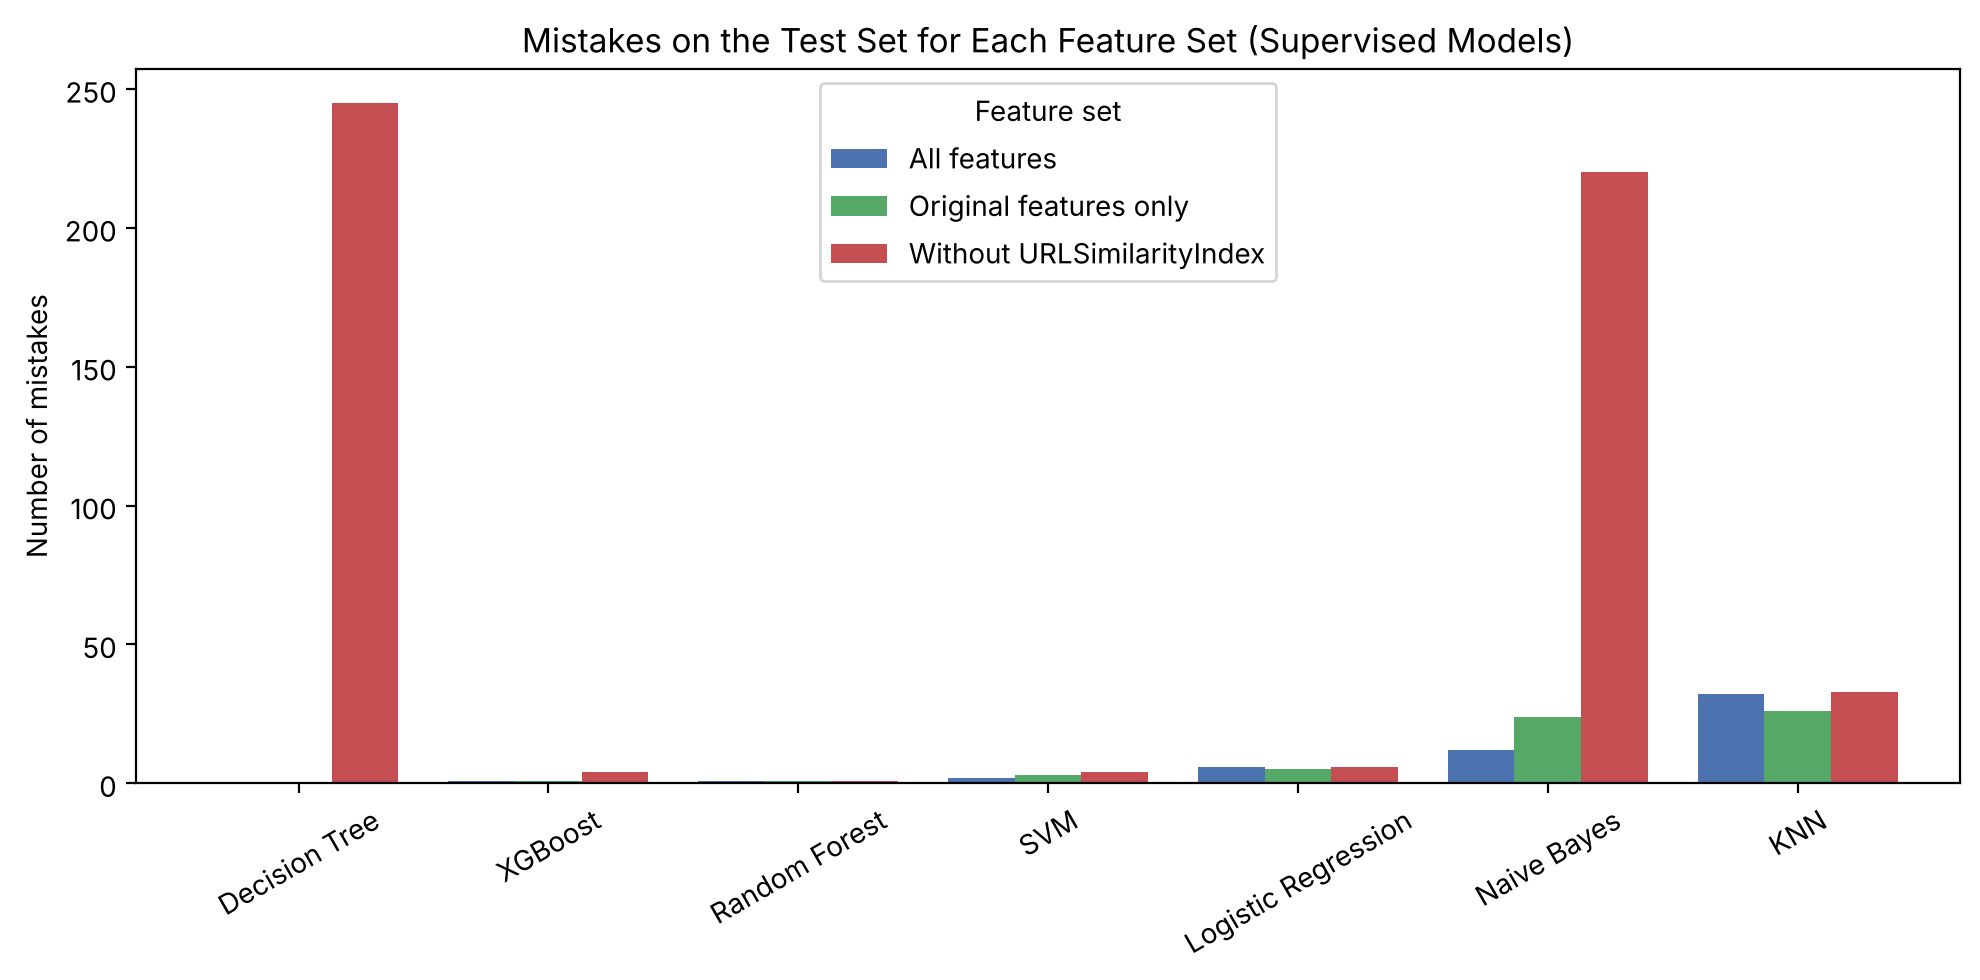

In [7]:
plot_table = feature_table.drop(index="Isolation Forest")

fig, ax = plt.subplots(figsize=(10, 5))
plot_table.plot.bar(ax=ax, color=["#4C72B0", "#55A868", "#C44E52"], width=0.8)
ax.set_title("Mistakes on the Test Set for Each Feature Set (Supervised Models)")
ax.set_ylabel("Number of mistakes")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Feature set")
fig.tight_layout()
fig.savefig(SAVE_DIR / "feature_set_comparison.png", dpi=300)
plt.show()

## 5. Training Time

A good model should also be fast to train, so it is easy to retrain when new phishing URLs appear.

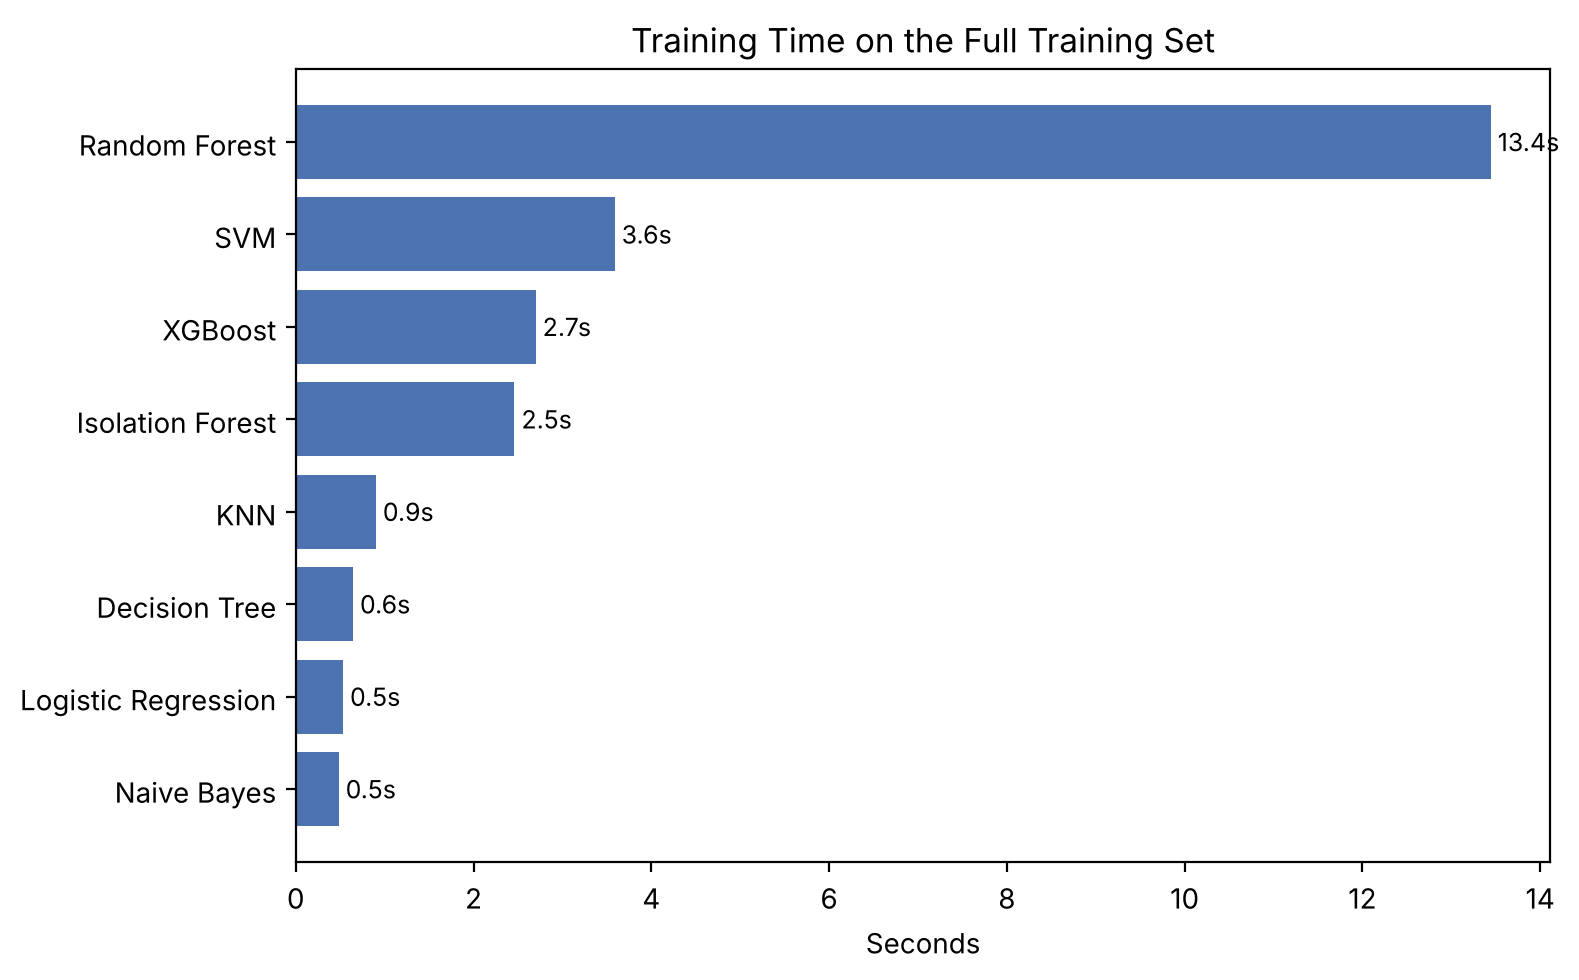

In [8]:
train_time = test_table["Train Time (s)"].sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(train_time.index, train_time.values, color=COLOR)
ax.set_title("Training Time on the Full Training Set")
ax.set_xlabel("Seconds")
for i, v in enumerate(train_time.values):
    ax.text(v, i, f" {v:.1f}s", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(SAVE_DIR / "training_time.png", dpi=300)
plt.show()

## 6. Save the Comparison Table

We save one final table with the main results of every model. We will use this table in the report.

In [9]:
comparison = test_table.join(feature_table[["Without URLSimilarityIndex"]].rename(columns={"Without URLSimilarityIndex": "Mistakes Without URLSimilarityIndex"}))
comparison = comparison.join(overfit_table[["Cross-validation F1"]])
comparison.to_csv(SAVE_DIR / "model_comparison.csv")
comparison.round(4)

,Type,Accuracy,Precision,Recall,F1,ROC-AUC,Mistakes,Train Time (s),Mistakes Without URLSimilarityIndex,Cross-validation F1
Model,,,,,,,,,,
Decision Tree,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,0,0.6433,245,1.0000
XGBoost,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,1,2.6984,4,1.0000
Random Forest,Supervised,1.0000,1.0000,1.0000,1.0000,1.0000,1,13.4427,1,1.0000
SVM,Supervised,1.0000,1.0000,0.9999,1.0000,1.0000,2,3.5873,4,0.9999
Logistic Regression,Supervised,0.9999,1.0000,0.9997,0.9999,1.0000,6,0.5311,6,0.9999
Naive Bayes,Supervised,0.9997,0.9995,1.0000,0.9997,0.9999,12,0.4819,220,0.9996
KNN,Supervised,0.9993,0.9999,0.9985,0.9992,0.9997,32,0.9004,33,0.9986
Isolation Forest,Unsupervised,0.8989,0.8727,0.8935,0.8830,0.9606,4761,2.4596,4917,0.8796


## 7. Findings

- **All supervised models are almost perfect.** The 7 supervised models made between 0 and 32 mistakes on 47,074 test URLs (accuracy 99.93% or more). This shows that the PhiUSIIL features separate phishing and legitimate URLs very clearly.
- **Top models:** Decision Tree made 0 mistakes, XGBoost and Random Forest made 1 mistake each, and SVM made 2. Logistic Regression (6), Naive Bayes (12) and KNN (32) were a little behind.
- **Isolation Forest is much weaker** (accuracy 89.9%, 4,761 mistakes). This is expected, because it is unsupervised. It never sees the labels during training and only learns what normal (legitimate) URLs look like.
- **No overfitting:** For every model the cross-validation F1 and the test F1 are almost the same (difference 0.0001 or less for the supervised models). So the models work as well on new URLs as on the training data.
- **New features:** Using only the original features gave almost the same results. On this dataset the original features are already strong, so feature engineering did not change Experiment 1 much. Naive Bayes is the one exception: it made 24 mistakes with the original features only and 12 with all features, so our new features halved its mistakes.
- **Without `URLSimilarityIndex`:** Decision Tree (0 → 245 mistakes) and Naive Bayes (12 → 220) depend heavily on this one feature. Random Forest (1 → 1), Logistic Regression (6 → 6), SVM and XGBoost hardly changed, because they use many features together.
- **Training time:** All supervised models trained in under 15 seconds on 188,296 URLs. Random Forest was the slowest (13.4 s) and Naive Bayes and Logistic Regression were the fastest (about 0.5 s).

### Best Model

We choose **Random Forest** as the best model for Experiment 1.

- It made only **1 mistake** and never called a legitimate URL phishing (precision 100%).
- It is the **most robust** model: removing `URLSimilarityIndex` did not change its result at all, while the Decision Tree, which scored a perfect 0, made 245 mistakes without it.
- It spreads its decisions over many features (see `05_random_forest.ipynb`), so it is less likely to fail if one feature is missing or wrong.
- Its cross-validation score is stable, and a training time of 13 seconds is still fast.

XGBoost is a very close second (1 mistake, 4 without `URLSimilarityIndex`).

**Note:** These near-perfect scores are on PhiUSIIL only. In Experiment 2 all models dropped to about 50% on the external dataset, so the next step is to make the models work on URLs from other sources.